# Wine Quality Prediction Using XGBoost and LightGBM with Hyperparameter Tuning

**Task:** Multiclass Classification  
**Dataset:** WineQT.csv  
**Models:** XGBoost and LightGBM

## Workflow
Dataset → Cleaning → EDA → Preprocessing → Baseline Models → Class Imbalance Experiment → Hyperparameter Tuning → Evaluation → Comparison → Confusion Matrix → Feature Importance → Final Model → Prediction → Save Model


## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load Dataset

In [ ]:
df = pd.read_csv("/content/WineQT.csv")

print("Shape:", df.shape)
df.head()


Shape: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [ ]:
print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [ ]:
print("Statistical Summary:")
df.describe()


Statistical Summary:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


## 3. Data Quality Checks

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique quality values:", sorted(df["quality"].unique()))


Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Duplicate rows: 0

Unique quality values: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


## 4. Exploratory Data Analysis

quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64


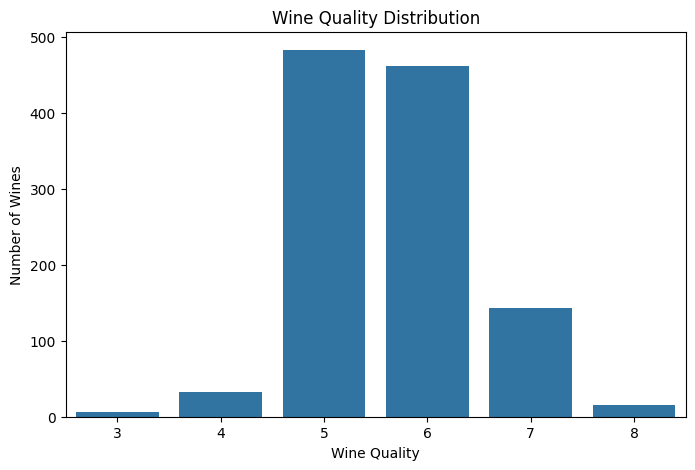

In [ ]:
quality_counts = df["quality"].value_counts().sort_index()
print(quality_counts)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality", order=sorted(df["quality"].unique()))
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")
plt.title("Wine Quality Distribution")
plt.show()


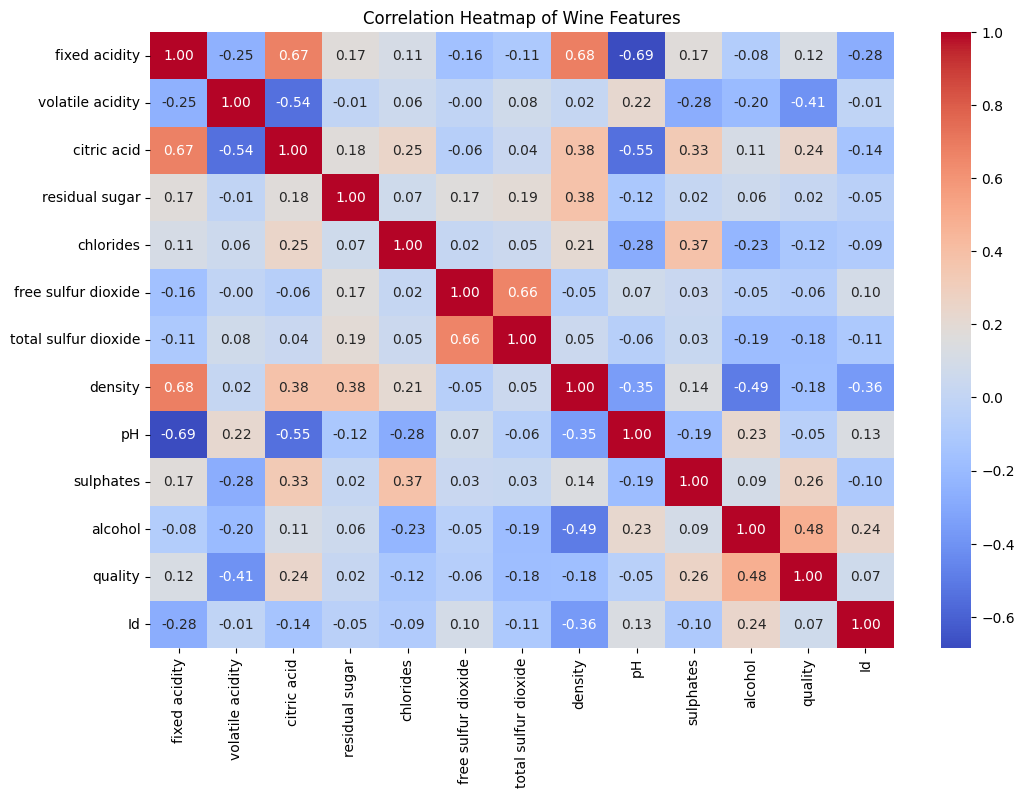

In [ ]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Wine Features")
plt.show()


In [ ]:
print("Correlation with Quality:")
print(correlation["quality"].sort_values(ascending=False))


Correlation with Quality:
quality                 1.000000
alcohol                 0.484866
sulphates               0.257710
citric acid             0.240821
fixed acidity           0.121970
Id                      0.069708
residual sugar          0.022002
pH                     -0.052453
free sulfur dioxide    -0.063260
chlorides              -0.124085
density                -0.175208
total sulfur dioxide   -0.183339
volatile acidity       -0.407394
Name: quality, dtype: float64


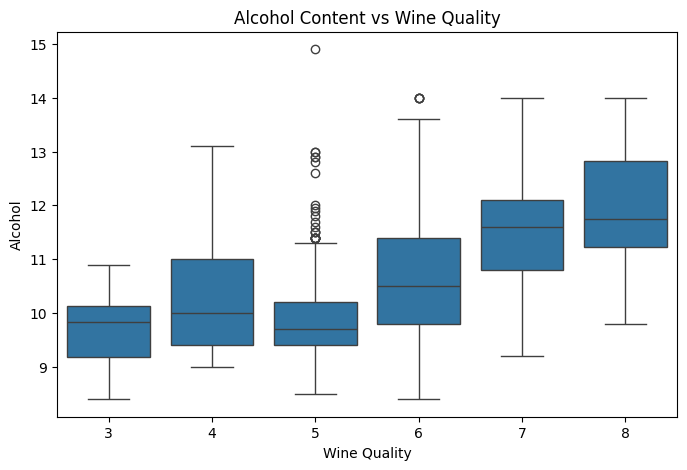

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="quality", y="alcohol")
plt.xlabel("Wine Quality")
plt.ylabel("Alcohol")
plt.title("Alcohol Content vs Wine Quality")
plt.show()


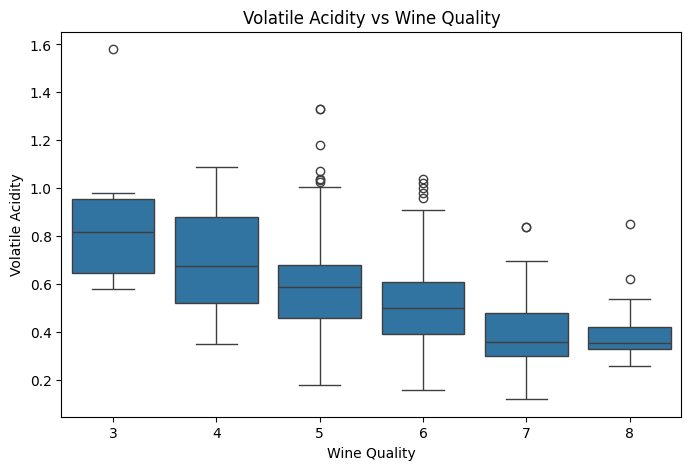

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="quality", y="volatile acidity")
plt.xlabel("Wine Quality")
plt.ylabel("Volatile Acidity")
plt.title("Volatile Acidity vs Wine Quality")
plt.show()


## 5. Data Preparation

In [ ]:
# Id is an identifier, so it is removed before modeling.
df = df.drop("Id", axis=1)

X = df.drop("quality", axis=1)
y = df["quality"]

print("Features:", list(X.columns))
print("X shape:", X.shape)
print("y shape:", y.shape)


Features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
X shape: (1143, 11)
y shape: (1143,)


## 6. Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test.value_counts().sort_index())


X_train: (914, 11)
X_test : (229, 11)
y_train: (914,)
y_test : (229,)

Training distribution:
quality
3      5
4     26
5    386
6    370
7    114
8     13
Name: count, dtype: int64

Testing distribution:
quality
3     1
4     7
5    97
6    92
7    29
8     3
Name: count, dtype: int64


## 7. Target Encoding

In [ ]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Original classes:", label_encoder.classes_)
print("Encoded classes:", sorted(set(y_train_encoded)))


Original classes: [3 4 5 6 7 8]
Encoded classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## 8. Baseline XGBoost

In [ ]:
xgb_model = XGBClassifier(
    objective="multi:softmax",
    num_class=6,
    random_state=42
)

xgb_model.fit(X_train, y_train_encoded)
y_pred_xgb = xgb_model.predict(X_test)

print("Baseline XGBoost trained.")


Baseline XGBoost trained.


In [ ]:
xgb_accuracy = accuracy_score(y_test_encoded, y_pred_xgb)
xgb_precision = precision_score(y_test_encoded, y_pred_xgb, average="weighted", zero_division=0)
xgb_recall = recall_score(y_test_encoded, y_pred_xgb, average="weighted", zero_division=0)
xgb_f1 = f1_score(y_test_encoded, y_pred_xgb, average="weighted", zero_division=0)
xgb_macro_f1 = f1_score(y_test_encoded, y_pred_xgb, average="macro", zero_division=0)

print(f"Accuracy    : {xgb_accuracy*100:.2f}%")
print(f"Precision   : {xgb_precision*100:.2f}%")
print(f"Recall      : {xgb_recall*100:.2f}%")
print(f"Weighted F1 : {xgb_f1*100:.2f}%")
print(f"Macro F1    : {xgb_macro_f1*100:.2f}%")


Accuracy    : 67.69%
Precision   : 65.88%
Recall      : 67.69%
Weighted F1 : 66.65%
Macro F1    : 39.82%


In [ ]:
print(classification_report(
    y_test_encoded,
    y_pred_xgb,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=[str(x) for x in label_encoder.classes_],
    zero_division=0
))


              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.72      0.80      0.76        97
           6       0.68      0.65      0.67        92
           7       0.57      0.55      0.56        29
           8       0.50      0.33      0.40         3

    accuracy                           0.68       229
   macro avg       0.41      0.39      0.40       229
weighted avg       0.66      0.68      0.67       229



## 9. Class Imbalance Experiment

In [ ]:
classes = np.unique(y_train_encoded)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_encoded
)

class_weight_dict = dict(zip(classes, class_weights))

for c, w in class_weight_dict.items():
    print(f"Quality {label_encoder.inverse_transform([c])[0]} : {w:.2f}")


Quality 3 : 30.47
Quality 4 : 5.86
Quality 5 : 0.39
Quality 6 : 0.41
Quality 7 : 1.34
Quality 8 : 11.72


In [ ]:
sample_weights = np.array([
    class_weight_dict[c] for c in y_train_encoded
])

xgb_weighted = XGBClassifier(
    objective="multi:softmax",
    num_class=6,
    random_state=42
)

xgb_weighted.fit(
    X_train,
    y_train_encoded,
    sample_weight=sample_weights
)

y_pred_xgb_weighted = xgb_weighted.predict(X_test)

weighted_accuracy = accuracy_score(y_test_encoded, y_pred_xgb_weighted)
weighted_precision = precision_score(y_test_encoded, y_pred_xgb_weighted, average="weighted", zero_division=0)
weighted_recall = recall_score(y_test_encoded, y_pred_xgb_weighted, average="weighted", zero_division=0)
weighted_f1 = f1_score(y_test_encoded, y_pred_xgb_weighted, average="weighted", zero_division=0)
weighted_macro_f1 = f1_score(y_test_encoded, y_pred_xgb_weighted, average="macro", zero_division=0)

print(f"Accuracy    : {weighted_accuracy*100:.2f}%")
print(f"Precision   : {weighted_precision*100:.2f}%")
print(f"Recall      : {weighted_recall*100:.2f}%")
print(f"Weighted F1 : {weighted_f1*100:.2f}%")
print(f"Macro F1    : {weighted_macro_f1*100:.2f}%")


Accuracy    : 65.94%
Precision   : 64.58%
Recall      : 65.94%
Weighted F1 : 65.08%
Macro F1    : 38.66%


## 10. XGBoost Hyperparameter Tuning

In [ ]:
xgb_param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.15, 0.2],
    "min_child_weight": [1, 3, 5, 7],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

xgb_tuning = XGBClassifier(
    objective="multi:softmax",
    num_class=6,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=xgb_tuning,
    param_distributions=xgb_param_grid,
    n_iter=20,
    scoring="f1_macro",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train_encoded)

print("Best parameters:")
print(random_search.best_params_)
print("\nBest CV Macro F1:", random_search.best_score_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters:
{'subsample': 0.8, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.7}

Best CV Macro F1: 0.3517877141940846


In [ ]:
best_xgb = random_search.best_estimator_
y_pred_tuned = best_xgb.predict(X_test)

tuned_xgb_accuracy = accuracy_score(y_test_encoded, y_pred_tuned)
tuned_xgb_precision = precision_score(y_test_encoded, y_pred_tuned, average="weighted", zero_division=0)
tuned_xgb_recall = recall_score(y_test_encoded, y_pred_tuned, average="weighted", zero_division=0)
tuned_xgb_f1 = f1_score(y_test_encoded, y_pred_tuned, average="weighted", zero_division=0)
tuned_xgb_macro_f1 = f1_score(y_test_encoded, y_pred_tuned, average="macro", zero_division=0)

print("Tuned XGBoost")
print(f"Accuracy    : {tuned_xgb_accuracy*100:.2f}%")
print(f"Precision   : {tuned_xgb_precision*100:.2f}%")
print(f"Recall      : {tuned_xgb_recall*100:.2f}%")
print(f"Weighted F1 : {tuned_xgb_f1*100:.2f}%")
print(f"Macro F1    : {tuned_xgb_macro_f1*100:.2f}%")


Tuned XGBoost
Accuracy    : 69.87%
Precision   : 67.23%
Recall      : 69.87%
Weighted F1 : 68.32%
Macro F1    : 41.12%


In [ ]:
print(classification_report(
    y_test_encoded,
    y_pred_tuned,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=[str(x) for x in label_encoder.classes_],
    zero_division=0
))


              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.73      0.81      0.77        97
           6       0.67      0.70      0.68        92
           7       0.70      0.55      0.62        29
           8       0.50      0.33      0.40         3

    accuracy                           0.70       229
   macro avg       0.43      0.40      0.41       229
weighted avg       0.67      0.70      0.68       229



## 11. Baseline LightGBM

In [ ]:
lgb_model = LGBMClassifier(
    objective="multiclass",
    num_class=6,
    random_state=42,
    verbosity=-1
)

lgb_model.fit(X_train, y_train_encoded)

y_pred_lgb = np.asarray(
    lgb_model.predict(X_test)
).astype(int).ravel()

print("Baseline LightGBM trained.")


Baseline LightGBM trained.


In [ ]:
lgb_accuracy = accuracy_score(y_test_encoded, y_pred_lgb)
lgb_precision = precision_score(y_test_encoded, y_pred_lgb, average="weighted", zero_division=0)
lgb_recall = recall_score(y_test_encoded, y_pred_lgb, average="weighted", zero_division=0)
lgb_f1 = f1_score(y_test_encoded, y_pred_lgb, average="weighted", zero_division=0)
lgb_macro_f1 = f1_score(y_test_encoded, y_pred_lgb, average="macro", zero_division=0)

print(f"Accuracy    : {lgb_accuracy*100:.2f}%")
print(f"Precision   : {lgb_precision*100:.2f}%")
print(f"Recall      : {lgb_recall*100:.2f}%")
print(f"Weighted F1 : {lgb_f1*100:.2f}%")
print(f"Macro F1    : {lgb_macro_f1*100:.2f}%")


Accuracy    : 68.56%
Precision   : 66.07%
Recall      : 68.56%
Weighted F1 : 66.98%
Macro F1    : 34.40%


## 12. LightGBM Hyperparameter Tuning

In [ ]:
lgb_param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "learning_rate": [0.01, 0.05, 0.1, 0.15, 0.2],
    "num_leaves": [15, 20, 31, 40, 50],
    "max_depth": [-1, 3, 4, 5, 6],
    "min_child_samples": [10, 20, 30, 40, 50],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

lgb_tuning = LGBMClassifier(
    objective="multiclass",
    num_class=6,
    random_state=42,
    verbosity=-1
)

lgb_random_search = RandomizedSearchCV(
    estimator=lgb_tuning,
    param_distributions=lgb_param_grid,
    n_iter=20,
    scoring="f1_macro",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

lgb_random_search.fit(X_train, y_train_encoded)

print("Best parameters:")
print(lgb_random_search.best_params_)
print("\nBest CV Macro F1:", lgb_random_search.best_score_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters:
{'subsample': 1.0, 'num_leaves': 50, 'n_estimators': 300, 'min_child_samples': 30, 'max_depth': 6, 'learning_rate': 0.15, 'colsample_bytree': 1.0}

Best CV Macro F1: 0.3667447932026866


In [ ]:
best_lgb = lgb_random_search.best_estimator_

y_pred_lgb_tuned = np.asarray(
    best_lgb.predict(X_test)
).astype(int).ravel()

tuned_lgb_accuracy = accuracy_score(y_test_encoded, y_pred_lgb_tuned)
tuned_lgb_precision = precision_score(y_test_encoded, y_pred_lgb_tuned, average="weighted", zero_division=0)
tuned_lgb_recall = recall_score(y_test_encoded, y_pred_lgb_tuned, average="weighted", zero_division=0)
tuned_lgb_f1 = f1_score(y_test_encoded, y_pred_lgb_tuned, average="weighted", zero_division=0)
tuned_lgb_macro_f1 = f1_score(y_test_encoded, y_pred_lgb_tuned, average="macro", zero_division=0)

print("Tuned LightGBM")
print(f"Accuracy    : {tuned_lgb_accuracy*100:.2f}%")
print(f"Precision   : {tuned_lgb_precision*100:.2f}%")
print(f"Recall      : {tuned_lgb_recall*100:.2f}%")
print(f"Weighted F1 : {tuned_lgb_f1*100:.2f}%")
print(f"Macro F1    : {tuned_lgb_macro_f1*100:.2f}%")


Tuned LightGBM
Accuracy    : 66.81%
Precision   : 64.44%
Recall      : 66.81%
Weighted F1 : 65.44%
Macro F1    : 33.49%


In [ ]:
print(classification_report(
    y_test_encoded,
    y_pred_lgb_tuned,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=[str(x) for x in label_encoder.classes_],
    zero_division=0
))


              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.72      0.78      0.75        97
           6       0.63      0.66      0.65        92
           7       0.70      0.55      0.62        29
           8       0.00      0.00      0.00         3

    accuracy                           0.67       229
   macro avg       0.34      0.33      0.33       229
weighted avg       0.64      0.67      0.65       229



## 13. Complete Performance Comparison

In [ ]:
performance = pd.DataFrame({
    "Model": [
        "XGBoost Baseline",
        "XGBoost Weighted",
        "XGBoost Tuned",
        "LightGBM Baseline",
        "LightGBM Tuned"
    ],
    "Accuracy": [
        xgb_accuracy*100,
        weighted_accuracy*100,
        tuned_xgb_accuracy*100,
        lgb_accuracy*100,
        tuned_lgb_accuracy*100
    ],
    "Precision": [
        xgb_precision*100,
        weighted_precision*100,
        tuned_xgb_precision*100,
        lgb_precision*100,
        tuned_lgb_precision*100
    ],
    "Recall": [
        xgb_recall*100,
        weighted_recall*100,
        tuned_xgb_recall*100,
        lgb_recall*100,
        tuned_lgb_recall*100
    ],
    "Weighted F1": [
        xgb_f1*100,
        weighted_f1*100,
        tuned_xgb_f1*100,
        lgb_f1*100,
        tuned_lgb_f1*100
    ],
    "Macro F1": [
        xgb_macro_f1*100,
        weighted_macro_f1*100,
        tuned_xgb_macro_f1*100,
        lgb_macro_f1*100,
        tuned_lgb_macro_f1*100
    ]
})

performance.round(2)


,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,XGBoost Baseline,67.69,65.88,67.69,66.65,39.82
1,XGBoost Weighted,65.94,64.58,65.94,65.08,38.66
2,XGBoost Tuned,69.87,67.23,69.87,68.32,41.12
3,LightGBM Baseline,68.56,66.07,68.56,66.98,34.40
4,LightGBM Tuned,66.81,64.44,66.81,65.44,33.49


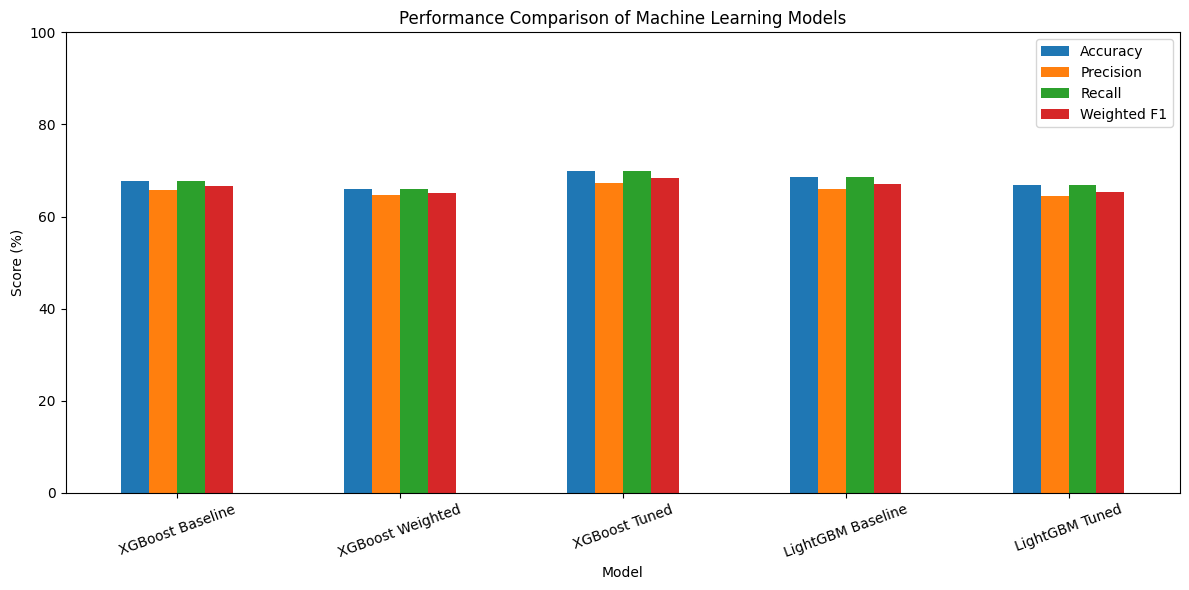

In [ ]:
performance.plot(
    x="Model",
    y=["Accuracy", "Precision", "Recall", "Weighted F1"],
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.title("Performance Comparison of Machine Learning Models")
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


## 14. Confusion Matrix — Tuned XGBoost

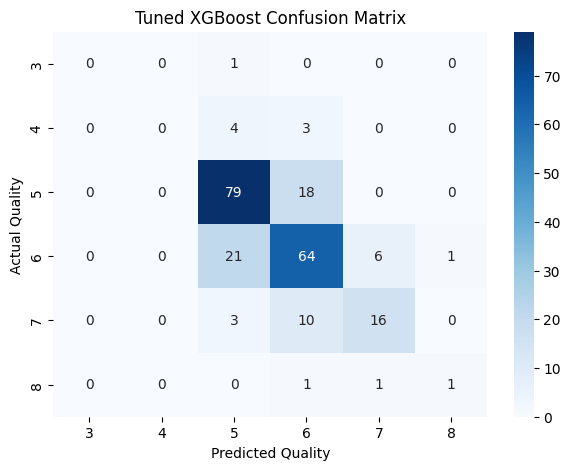

In [ ]:
cm_xgb = confusion_matrix(y_test_encoded, y_pred_tuned)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.title("Tuned XGBoost Confusion Matrix")
plt.show()


## 15. Feature Importance — Tuned XGBoost

In [ ]:
feature_importance = pd.Series(
    best_xgb.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(feature_importance)


alcohol                 0.151187
volatile acidity        0.110118
sulphates               0.107199
total sulfur dioxide    0.095316
citric acid             0.086466
pH                      0.080658
free sulfur dioxide     0.077607
density                 0.075298
chlorides               0.075271
residual sugar          0.070623
fixed acidity           0.070256
dtype: float32


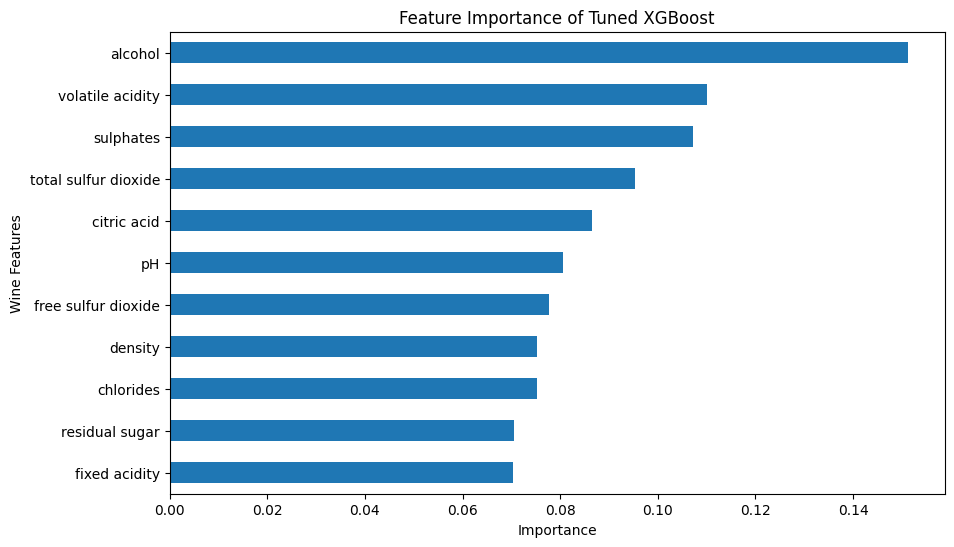

In [ ]:
plt.figure(figsize=(10, 6))
feature_importance.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.ylabel("Wine Features")
plt.title("Feature Importance of Tuned XGBoost")
plt.show()


## 16. Final Model Selection

In [ ]:
# This explicitly selects the tuned XGBoost model as the final model.
final_model = best_xgb

print("Final Model: Tuned XGBoost")
print("\nBest Parameters:")
print(random_search.best_params_)

print("\nFinal Test Metrics:")
print(f"Accuracy    : {tuned_xgb_accuracy*100:.2f}%")
print(f"Precision   : {tuned_xgb_precision*100:.2f}%")
print(f"Recall      : {tuned_xgb_recall*100:.2f}%")
print(f"Weighted F1 : {tuned_xgb_f1*100:.2f}%")
print(f"Macro F1    : {tuned_xgb_macro_f1*100:.2f}%")


Final Model: Tuned XGBoost

Best Parameters:
{'subsample': 0.8, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.7}

Final Test Metrics:
Accuracy    : 69.87%
Precision   : 67.23%
Recall      : 69.87%
Weighted F1 : 68.32%
Macro F1    : 41.12%


## 17. Final Prediction Demo

In [ ]:
# Use one existing test sample for a prediction demonstration.
sample = X_test.iloc[[0]]

predicted_encoded = final_model.predict(sample)

predicted_quality = label_encoder.inverse_transform(
    np.asarray(predicted_encoded).astype(int)
)

print("Predicted Quality:", predicted_quality[0])
print("Actual Quality   :", y_test.iloc[0])


Predicted Quality: 6
Actual Quality   : 6


## 18. Save Final Model

In [ ]:
joblib.dump(final_model, "wine_quality_xgboost.pkl")
joblib.dump(label_encoder, "wine_quality_label_encoder.pkl")

print("Saved:")
print("1. wine_quality_xgboost.pkl")
print("2. wine_quality_label_encoder.pkl")


Saved:
1. wine_quality_xgboost.pkl
2. wine_quality_label_encoder.pkl


In [ ]:
import joblib
import os
import zipfile
from google.colab import files

# Save the final tuned XGBoost model
joblib.dump(final_model, "wine_quality_model.pkl")

# Save the target label encoder
joblib.dump(label_encoder, "wine_quality_label_encoder.pkl")

# Save the dataset for the Data Exploration page
df.to_csv("WineQT.csv", index=False)

# Package the files
with zipfile.ZipFile("wine_quality_website_files.zip", "w") as z:
    z.write("wine_quality_model.pkl")
    z.write("wine_quality_label_encoder.pkl")
    z.write("WineQT.csv")

files.download("wine_quality_website_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import xgboost as xgb
import joblib
import zipfile
from google.colab import files

# Save the tuned XGBoost model in JSON format
final_model.save_model("wine_quality_model.json")

# Save the label encoder
joblib.dump(
    label_encoder,
    "wine_quality_label_encoder.pkl"
)

# Include the dataset for the website
df.to_csv("WineQT.csv", index=False)

# Create a ZIP file
with zipfile.ZipFile("wine_quality_website_files.zip", "w") as z:
    z.write("wine_quality_model.json")
    z.write("wine_quality_label_encoder.pkl")
    z.write("WineQT.csv")

files.download("wine_quality_website_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Final Project Conclusion

The project predicts wine quality as a **multiclass classification problem** using physicochemical wine properties.

Two gradient-boosting models were evaluated:
- XGBoost
- LightGBM

Hyperparameter tuning was performed using `RandomizedSearchCV` with **Macro F1** as the optimization metric.

For the current held-out test split, the tuned XGBoost model achieved approximately:
- **Accuracy:** 69.87%
- **Weighted F1:** 68.32%
- **Macro F1:** 41.12%

The dataset is imbalanced, especially for quality classes 3, 4, and 8, so macro F1 and per-class metrics should be considered along with accuracy.

**Final model:** Tuned XGBoost.
